
<div align="center">

<h2><strong>PEMBUATAN RECIPE UNTUK MODEL PANAS BAWAH PERMUKAAN BERLAPIS DENGAN SEASONAL FORCING</strong></h2>
<h3><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h3>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png"
     alt="Logo Universitas Hasanuddin"
     style="width:220px; margin:20px 0;">

<h5><strong>Oleh:</strong></h5>
<p><strong>SITTI AISYAH IBRAHIM</strong></p>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>2026</strong></p>

</div>


## **STUDI KASUS**

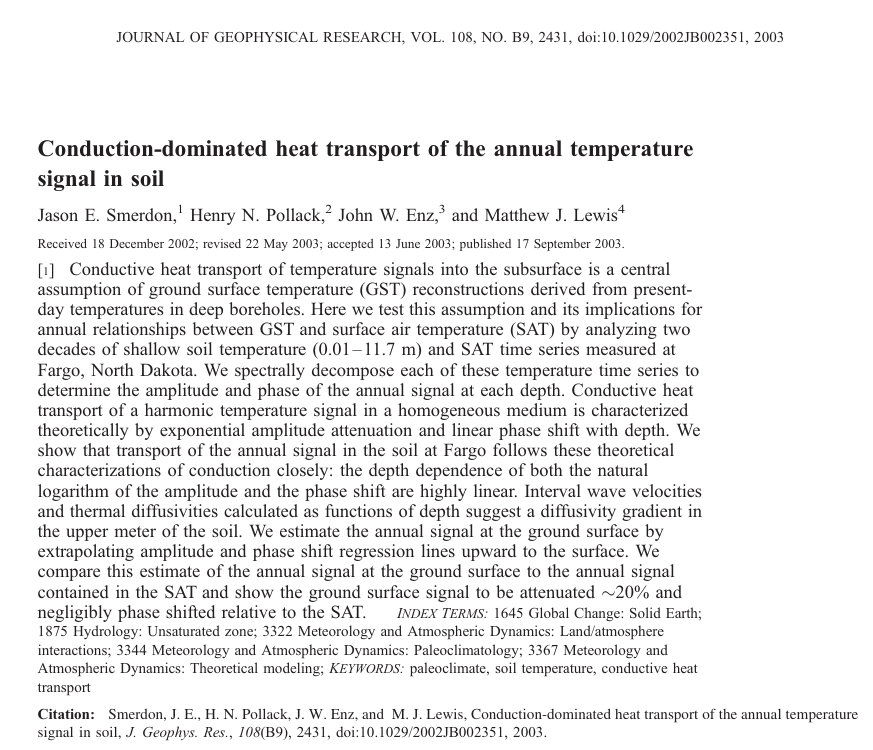

### Model Panas Bawah Permukaan Berlapis dengan Seasonal Forcing (R-MOD-002)

Perubahan temperatur di permukaan bumi akibat pergantian musim dapat merambat ke bawah permukaan melalui proses konduksi panas. Namun, perubahan temperatur tersebut tidak diteruskan dengan amplitudo yang sama pada setiap kedalaman. Semakin dalam posisi suatu lapisan, respons temperatur umumnya semakin teredam dan waktu terjadinya temperatur maksimum atau minimum dapat bergeser.

Pada studi kasus ini, bawah permukaan dimodelkan sebagai dua lapisan, yaitu lapisan tanah bagian atas hingga kedalaman 2,5 m dan lapisan batuan di bawahnya. Kedua lapisan memiliki nilai difusivitas termal yang berbeda. Temperatur permukaan diberikan sebagai fungsi sinusoidal dengan periode 365 hari, sedangkan temperatur pada batas bawah dijaga tetap sebesar 22°C. Simulasi dilakukan untuk mengamati perubahan temperatur terhadap waktu dan kedalaman serta melihat pengaruh perbedaan sifat termal antarlapisan.

Model ini merupakan simulasi numerik sintetis, bukan prediksi temperatur lokasi tertentu karena tidak menggunakan data pengukuran lapangan.


Jumlah titik kedalaman : 81
Jumlah langkah waktu   : 4380
Rasio stabilitas maksimum: 0.384
Status stabilitas: memenuhi kriteria r <= 0.5
\nRingkasan temperatur selama tahun simulasi:
Kedalaman (m) | Tmin (°C) | Tmax (°C) | Half-range (°C)
         0.00 |    14.00 |    34.00 |          10.00
         0.45 |    16.02 |    32.30 |           8.14
         1.50 |    18.89 |    29.70 |           5.40
         3.00 |    20.60 |    27.79 |           3.60
         6.00 |    22.27 |    25.34 |           1.53


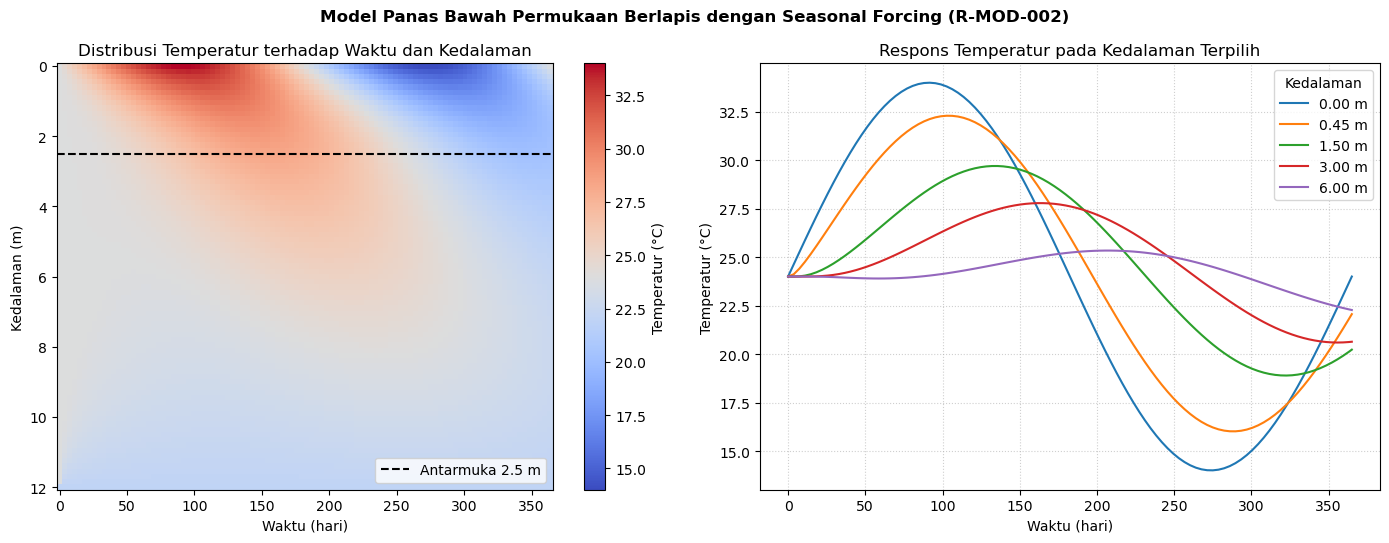

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================================
# 1. PARAMETER MODEL DAN KISI KEDALAMAN
# ==========================================================
max_depth_m = 12.0
dz_m = 0.15
total_days = 365.0

# Langkah waktu dibuat 2 jam agar memenuhi kriteria stabilitas
# untuk skema beda hingga eksplisit pada parameter model ini.
dt_hours = 2.0

interface_depth_m = 2.5
kappa_soil = 0.4e-6       # Difusivitas termal tanah (m^2/s)
kappa_rock = 1.2e-6       # Difusivitas termal batuan (m^2/s)

T_mean = 24.0             # Temperatur rata-rata permukaan (°C)
T_amplitude = 10.0        # Amplitudo forcing permukaan (°C)
T_bottom = 22.0           # Temperatur batas bawah tetap (°C)

z_grid = np.arange(0.0, max_depth_m + dz_m, dz_m)
dt_s = dt_hours * 3600.0
nsteps_season = int(round(total_days * 24.0 / dt_hours))

# Difusivitas termal untuk setiap titik kedalaman
kappa_array = np.where(z_grid <= interface_depth_m,
                       kappa_soil, kappa_rock)

# Pemeriksaan stabilitas skema eksplisit: r <= 0.5
r_ratio_max = np.max(kappa_array) * dt_s / dz_m**2
print(f"Jumlah titik kedalaman : {len(z_grid)}")
print(f"Jumlah langkah waktu   : {nsteps_season}")
print(f"Rasio stabilitas maksimum: {r_ratio_max:.3f}")

if r_ratio_max <= 0.5:
    print("Status stabilitas: memenuhi kriteria r <= 0.5")
else:
    print("Status stabilitas: tidak memenuhi kriteria r <= 0.5; kecilkan dt_hours atau perbesar dz_m")

# ==========================================================
# 2. SIMULASI DIFUSI PANAS DENGAN FORCING SINUSOIDAL
# ==========================================================
temp_profile = np.full(len(z_grid), T_mean, dtype=float)
history_seasonal = []
record_days = []

save_freq = max(1, int(round(nsteps_season / 100)))

for step in range(nsteps_season + 1):
    t_day = step * dt_hours / 24.0

    # Boundary condition: temperatur permukaan berubah secara musiman
    temp_profile[0] = T_mean + T_amplitude * np.sin(
        2.0 * np.pi * t_day / 365.0
    )

    # Boundary condition: temperatur batas bawah tetap
    temp_profile[-1] = T_bottom

    if step % save_freq == 0 or step == nsteps_season:
        history_seasonal.append(temp_profile.copy())
        record_days.append(t_day)

    if step < nsteps_season:
        temp_next = temp_profile.copy()
        alpha = kappa_array[1:-1] * dt_s / dz_m**2

        # Skema beda hingga eksplisit untuk persamaan difusi panas 1D
        temp_next[1:-1] = (
            temp_profile[1:-1]
            + alpha * (
                temp_profile[2:]
                - 2.0 * temp_profile[1:-1]
                + temp_profile[:-2]
            )
        )
        temp_profile = temp_next

history_seasonal = np.asarray(history_seasonal)
record_days = np.asarray(record_days)

# ==========================================================
# 3. RINGKASAN TEMPERATUR PADA BEBERAPA KEDALAMAN
# ==========================================================
selected_depths = [0.0, 0.5, 1.5, 3.0, 6.0]
print("\\nRingkasan temperatur selama tahun simulasi:")
print("Kedalaman (m) | Tmin (°C) | Tmax (°C) | Half-range (°C)")
for depth in selected_depths:
    idx = int(np.argmin(np.abs(z_grid - depth)))
    values = history_seasonal[:, idx]
    half_range = (values.max() - values.min()) / 2.0
    print(f"{z_grid[idx]:13.2f} | {values.min():8.2f} | "
          f"{values.max():8.2f} | {half_range:14.2f}")

# ==========================================================
# 4. VISUALISASI HASIL MODEL
# ==========================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel A: perubahan temperatur terhadap waktu dan kedalaman
mesh = axes[0].pcolormesh(
    record_days, z_grid, history_seasonal.T,
    shading="auto", cmap="coolwarm"
)
axes[0].axhline(
    interface_depth_m, color="black", linestyle="--",
    linewidth=1.5, label=f"Antarmuka {interface_depth_m} m"
)
axes[0].set_title("Distribusi Temperatur terhadap Waktu dan Kedalaman")
axes[0].set_xlabel("Waktu (hari)")
axes[0].set_ylabel("Kedalaman (m)")
axes[0].invert_yaxis()
axes[0].legend(loc="lower right")
fig.colorbar(mesh, ax=axes[0], label="Temperatur (°C)")

# Panel B: temperatur pada kedalaman terpilih
for depth in selected_depths:
    idx = int(np.argmin(np.abs(z_grid - depth)))
    axes[1].plot(
        record_days, history_seasonal[:, idx],
        label=f"{z_grid[idx]:.2f} m"
    )

axes[1].set_title("Respons Temperatur pada Kedalaman Terpilih")
axes[1].set_xlabel("Waktu (hari)")
axes[1].set_ylabel("Temperatur (°C)")
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(title="Kedalaman")

plt.suptitle(
    "Model Panas Bawah Permukaan Berlapis dengan Seasonal Forcing (R-MOD-002)",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.show()



## **Analisis Hasil Pemodelan Panas Bawah Permukaan (R-MOD-002)**

Hasil simulasi memperlihatkan bahwa perubahan temperatur paling besar terjadi di dekat permukaan, kemudian semakin teredam pada kedalaman yang lebih besar. Pada permukaan, temperatur mengikuti forcing sinusoidal dengan nilai sekitar 14–34°C. Pada kedalaman 3 m, temperatur selama tahun simulasi berada sekitar 20,60–27,79°C, sedangkan pada kedalaman 6 m berada sekitar 22,27–25,34°C. Hal ini menunjukkan bahwa amplitudo perubahan temperatur berkurang seiring bertambahnya kedalaman.

Puncak temperatur juga muncul semakin lambat pada kedalaman yang lebih besar. Pada hasil simulasi tahun pertama ini, puncak temperatur permukaan terjadi sekitar hari ke-92, sedangkan pada kedalaman 3 m sekitar hari ke-165 dan pada 6 m sekitar hari ke-205. Pergeseran ini konsisten dengan respons termal yang tertunda selama panas merambat ke bawah permukaan. Namun, karena simulasi hanya mencakup satu tahun dan kondisi awal tidak sama dengan seluruh kondisi kesetimbangan musiman, angka tersebut perlu dipahami sebagai respons tahun pertama yang masih dapat mengandung pengaruh transien, bukan nilai fase periodik yang sudah stabil.

Pemeriksaan numerik menghasilkan rasio stabilitas maksimum sebesar 0,384, sehingga memenuhi kriteria \(r \leq 0,5\) untuk skema beda hingga eksplisit yang digunakan. Langkah waktu 2 jam dipilih agar simulasi memenuhi kriteria tersebut. Model ini tetap memiliki keterbatasan karena menggunakan konduksi panas 1D, properti termal yang konstan di tiap lapisan, dan batas bawah bertemperatur tetap. Model belum memasukkan pengaruh kadar air, aliran air tanah, sumber panas internal, atau data temperatur lapangan.

### **Referensi**

Smerdon, J. E., Pollack, H. N., Enz, J. W., & Lewis, M. J. (2003). *Conduction-dominated heat transport of the annual temperature signal in soil*. Journal of Geophysical Research: Solid Earth, 108(B9), 2431. https://doi.org/10.1029/2002JB002351
